In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

In [3]:
shocks = ["RS", "FS"]

In [10]:
termo_norm = {}

for shock in shocks:
    
    file_termo_norm = f"../../../output/termonorm_{shock}.dat"
    df = pd.read_csv(file_termo_norm, delim_whitespace=True)
    
    termo_norm[shock] = {
        "df": df,
        "theta": df.iloc[:,0]*180./np.pi,
        "rho": df.iloc[:,1],
        "P": df.iloc[:,2],
        "T": df.iloc[:,4],
        "B": df.iloc[:,5],
        "v_t": df.iloc[:,3],
        "v_perp": df.iloc[:,6],
        "cs": df.iloc[:,7]
    }

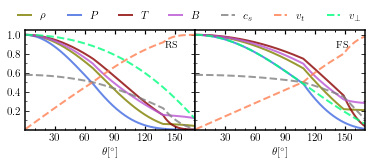

In [102]:
fig, ax = plt.subplots(1, 2, figsize=(text_width, 0.3*text_width),
                   sharex = True, sharey = True)

for i, shock in enumerate(shocks):
    
    axi = ax[i]
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["rho"],
            color='olive', lw=2, alpha=0.8,
            label=r"$\rho$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["P"],
            color='royalblue', lw=2, alpha=0.8,
            label=r"$P$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["T"],
            color='darkred', lw=2, alpha=0.8,
            label=r"$T$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["B"],
            color='mediumorchid', lw=2, alpha=0.8,
            label=r"$B$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["cs"],
            color='grey', lw=2, ls='--', alpha=0.8,
            label=r"$c_s$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["v_t"],
            color='coral', lw=2, ls='--', alpha=0.8,
            label=r"$v_t$")
    
    axi.plot(termo_norm[shock]["theta"],
            termo_norm[shock]["v_perp"],
            color='springgreen', lw=2, ls='--', alpha=0.8,
            label=r"$v_\perp$")
    
    axi.set_xlim(0,170.)
    axi.set_xticks([30., 60., 90., 120., 150.])
    axi.set_xticks([10, 20, 40, 50, 70, 80,
                      100, 110, 130, 140, 160], minor = True)
    
    axi.set_ylim(0,1.05)
    axi.set_yticks([0.2, 0.4, 0.6, 0.8, 1.])
    axi.set_yticks([0.1, 0.3, 0.5, 0.7, 0.9], minor = True)
    
    axi.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

    axi.annotate(
        f"{shock}",
        xy=(0.9, 0.90),
        xycoords="axes fraction",
        ha="right",
        va="top"
    )

    axi.xaxis.set_minor_formatter(NullFormatter())
    axi.yaxis.set_minor_formatter(NullFormatter())
    
    axi.set_xlabel(r"$\theta [^\circ]$")
    
handles, labels = ax[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=7,
    frameon=False,
    bbox_to_anchor=(0.5, 1.1),
    handlelength=1.2
)

# Figuras pegadas
fig.subplots_adjust(wspace=0)
    
plt.show()

In [103]:
#fig.savefig('termo_norm_HVSs.pdf', bbox_inches='tight', pad_inches = 0.01)

In [74]:
adi_RH = {}

for shock in shocks:
    
    file_adi_RH = f"../../../output/new_vs_RH_{shock}.dat"
    df = pd.read_csv(file_adi_RH, delim_whitespace=True)
    
    adi_RH[shock] = {
        "df": df,
        "theta": df.iloc[:,0]*180./np.pi,
        "rho": df.iloc[:,3],
        "P": df.iloc[:,2],
        "v_t": df.iloc[:,1],
    }

0      0.447217
1      0.447226
2      0.447242
3      0.447264
4      0.447293
         ...   
294    0.973717
295    0.976059
296    0.978284
297    0.980394
298    0.982391
Name: Infinity, Length: 299, dtype: float64


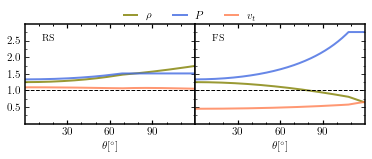

In [100]:
fig, ax = plt.subplots(1, 2, figsize=(text_width, 0.3*text_width),
                   sharex = True, sharey = True)

for i, shock in enumerate(shocks):
    
    axi = ax[i]
    
    axi.plot(adi_RH[shock]["theta"],
            adi_RH[shock]["rho"],
            color='olive', lw=2, alpha=0.8,
            label=r"$\rho$")
    
    axi.plot(adi_RH[shock]["theta"],
            adi_RH[shock]["P"],
            color='royalblue', lw=2, alpha=0.8,
            label=r"$P$")
    
    axi.plot(adi_RH[shock]["theta"],
            adi_RH[shock]["v_t"],
            color='coral', lw=2, alpha=0.8,
            label=r"$v_t$")
    
    axi.set_xlim(0,120.)
    axi.set_xticks([30., 60., 90.])
    axi.set_xticks([10, 20, 40, 50, 70, 80,
                      100, 110], minor = True)
    
    axi.set_ylim(0,3)
    axi.set_yticks([0.5, 1., 1.5, 2, 2.5])
    axi.set_yticks([0.25, 0.75, 1.25, 1.75, 2.25, 2.75], minor = True)
    
    axi.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

    axi.annotate(
        f"{shock}",
        xy=(0.1, 0.90),
        xycoords="axes fraction",
        ha="left",
        va="top"
    )

    axi.xaxis.set_minor_formatter(NullFormatter())
    axi.yaxis.set_minor_formatter(NullFormatter())
    
    axi.set_xlabel(r"$\theta [^\circ]$")
    
    # Línea vertical en 1
    axi.axhline(
        y=1,
        color="black",
        ls="--",
        lw=1
    )

    
handles, labels = ax[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=7,
    frameon=False,
    bbox_to_anchor=(0.5, 1.05),
    handlelength=1.2
)

# Figuras pegadas
fig.subplots_adjust(wspace=0)
    
plt.show()

In [101]:
#fig.savefig('new_termo_vs_RH_HVSs.pdf', bbox_inches='tight', pad_inches = 0.01)

In [82]:
scenarios = ["B0-05-d", "B1-1-d", "B1-1-h", "B1-1-mc", "B2-60-d"]

In [85]:
rad_adi = {}

for shock in shocks:
    rad_adi[shock] = {}
    for sc in scenarios:
        file_rad_adi = f"../../../output/rad_adi_{sc}_{shock}.dat"
        df = pd.read_csv(file_rad_adi, delim_whitespace=True)

        rad_adi[shock][sc] = {
            "df": df,
            "theta": df.iloc[:,0]*180./np.pi,
            "t_th/t_adv": df.iloc[:,1],
        }

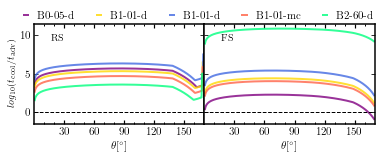

In [104]:
fig, ax = plt.subplots(1, 2, figsize=(text_width, 0.3*text_width),
                   sharex = True, sharey = True)

for i, shock in enumerate(shocks):
    
    axi = ax[i]
    
    axi.plot(rad_adi[shock]["B0-05-d"]["theta"],
            np.log10(rad_adi[shock]["B0-05-d"]["t_th/t_adv"]),
            color='purple', lw=2, alpha=0.8,
            label=r"B0-05-d")
    
    axi.plot(rad_adi[shock]["B1-1-d"]["theta"],
            np.log10(rad_adi[shock]["B1-1-d"]["t_th/t_adv"]),
            color='gold', lw=2, alpha=0.8,
            label=r"B1-01-d")
    
    axi.plot(rad_adi[shock]["B1-1-h"]["theta"],
            np.log10(rad_adi[shock]["B1-1-h"]["t_th/t_adv"]),
            color='royalblue', lw=2, alpha=0.8,
            label=r"B1-01-d")
    
    axi.plot(rad_adi[shock]["B1-1-mc"]["theta"],
            np.log10(rad_adi[shock]["B1-1-mc"]["t_th/t_adv"]),
            color='tomato', lw=2, alpha=0.8,
            label=r"B1-01-mc")
    
    axi.plot(rad_adi[shock]["B2-60-d"]["theta"],
            np.log10(rad_adi[shock]["B2-60-d"]["t_th/t_adv"]),
            color='springgreen', lw=2, alpha=0.8,
            label=r"B2-60-d")
    
    
    axi.set_xlim(0,170.)
    axi.set_xticks([30., 60., 90., 120., 150.])
    axi.set_xticks([10, 20, 40, 50, 70, 80,
                      100, 110, 130, 140, 160], minor = True)
    
    #axi.set_ylim(0,3)
    #axi.set_yticks([0.5, 1., 1.5, 2, 2.5])
    #axi.set_yticks([0.25, 0.75, 1.25, 1.75, 2.25, 2.75], minor = True)
    
    axi.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True
    )

    axi.annotate(
        f"{shock}",
        xy=(0.1, 0.90),
        xycoords="axes fraction",
        ha="left",
        va="top"
    )

    axi.xaxis.set_minor_formatter(NullFormatter())
    axi.yaxis.set_minor_formatter(NullFormatter())
    
    axi.set_xlabel(r"$\theta [^\circ]$")
    
    # Línea vertical en 1
    axi.axhline(
        y=0,
        color="black",
        ls="--",
        lw=1
    )
    
sp = fig.subplotpars
xmid = (sp.left + sp.right) / 2
ymid = (sp.bottom + sp.top) / 2

fig.text(
    sp.left - 0.05, ymid,
    r"$log_{10}(t_{\rm cool}/t_{\rm adv}) $",
    rotation='vertical',
    ha='center', va='center'
)

    
handles, labels = ax[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.05),
    handlelength=0.4
)

# Figuras pegadas
fig.subplots_adjust(wspace=0)
    
plt.show()

In [105]:
#fig.savefig('rad_adi_HVSs.pdf', bbox_inches='tight', pad_inches = 0.01)